# Figure S14: the TSS model with the covariates inside it

The five confounders (coverage, fragment count, plasma volume, age, sex) enter the same fully nested
model as the TSS features, next to the unchanged model:

| arm | features |
|---|---|
| `none` | TSS features only |
| `cov_techdemo5` | TSS features + the 5 confounders |

The covariates bypass the TSS ranking (always in the model, whatever *k*) and are column-scaled next
to the selected TSSs. Each arm is a k-sweep; the tuned model takes per fold the *k* with the best
inner-CV score. Partial results can be drawn while the sweeps run (Section 1 shows what is on disk).

`COHORT` defaults to `no_deep`; `FIG_COHORT=all` draws the full cohort. Source data: `figS14_*.csv`,
written by `export/export_figS14.py`.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch (no_deep is the default) ----------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
        p = os.path.join("data", name)
    return p


def out_path(name):
    return os.path.join(_OUT, name)


def savefig(fig, name, **kw):
    import time
    for attempt in range(4):
        try:
            fig.savefig(out_path(name), **kw); return
        except (FileNotFoundError, OSError):
            if attempt == 3: raise
            time.sleep(2 * (attempt + 1))


def load_opt(name):
    p = data_path(name)
    if not os.path.exists(p):
        print(f"   {name}: not available"); return None
    try:
        df = pd.read_csv(p)
    except pd.errors.EmptyDataError:
        return None
    return df if len(df) else None


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from sklearn.metrics import roc_curve, roc_auc_score

ARMS = {"none": dict(label="TSS only (manuscript model)", color="#0173B2"),
        "cov_techdemo5": dict(label="TSS + 5 covariates", color="#3B4A8C")}
TASKS = {"brca_crc": "BRCA/CRC", "pancan": "PANCAN"}
LABELS = {"mean_coverage": "Mean coverage", "total_fragments": "Total fragments",
          "plasma_volume": "Plasma volume", "age": "Age", "sex_female": "Sex (female)", "fragment_length_mean": "Fragment length",
          "mean_gc": "Mean fragment GC", "cfdna_extracted": "cfDNA concentration", "sex_female_bam": "Sex (from the BAM)"}
status = load_opt("figS14_status.csv"); folds = load_opt("figS14_folds.csv"); preds = load_opt("figS14_predictions.csv")
tuned = load_opt("figS14_tuned.csv"); blocks = load_opt("figS14_blocks.csv"); covs = load_opt("figS14_covariates.csv")
refs = load_opt("figS14_references.csv")
HAVE = folds is not None
if not HAVE:
    print("No Fig S14 source data yet: run the sweeps (slurm/submit_covariate_arms.sh) and python src/figures/export/export_figS14.py")


def arms_present(task):
    return [a for a in ARMS if HAVE and ((folds["task"] == task) & (folds["arm"] == a)).any()]


def mean_roc(df):
    base = np.linspace(0, 1, 101); tprs, aucs = [], []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"]); tprs.append(interp1d(fpr, tpr)(base)); aucs.append(roc_auc_score(g["y_true"], g["score"]))
    m = np.mean(tprs, axis=0); m[0], m[-1] = 0, 1
    return base, m, np.array(aucs)


# --- AUROC against k, with k = 0 = the covariate-only model ------------------------
# The covariate-only panel (Table S3, same outer folds) is drawn at K0_X, left of the axis break.
PANEL_OF = {"cov_techdemo5": "bl_panel_techdemo5"}
BL_FILE = {"brca_crc": "fig3_baseline_predictions.csv", "pancan": "fig4_baseline_predictions.csv"}
BL_PRED = {}
K0_X, K_BREAK = 4.0, 6.5


def panel_fold_aucs(task, arm):
    """Held-out AUROC per outer fold of the covariate-only panel that this arm contains."""
    if task not in BL_PRED:
        BL_PRED[task] = pd.read_csv(data_path(BL_FILE[task]))
    p = BL_PRED[task]
    q = p[(p["method"] == PANEL_OF[arm]) & p["score"].notna()]
    aucs = np.array([roc_auc_score(g["y_true"], g["score"] * g["orientation"].fillna(1.0)) for _, g in q.groupby("fold")])
    if refs is not None:
        r = refs[(refs["task"] == task) & (refs["arm"] == arm)]
        if len(r):
            assert np.isclose(aucs.mean(), r["auc_fold_mean"].iloc[0], atol=1e-6), (task, arm)
    return aucs


def k_text(k):
    return "all" if int(k) >= 15000 else f"{int(k):,}"


def draw_auc_vs_k(ax, task, arms_, label_of, ylim=(0.45, 1.01), point_size=9):
    """Mean held-out AUROC against k per arm, folds as light points, k = 0 = the panel alone (dotted level)."""
    for arm in arms_:
        col = ARMS[arm]["color"]
        g = folds[(folds["task"] == task) & (folds["arm"] == arm)]
        m = g.groupby("k")["test_auc"].agg(["mean", "count"]).reset_index()
        ax.scatter(g["k"], g["test_auc"], s=point_size, color=col, alpha=0.3)
        ax.plot(m["k"], m["mean"], marker="o", color=col, linewidth=2, label=label_of(arm, m))
        if arm in PANEL_OF:
            a = panel_fold_aucs(task, arm)
            ax.scatter(np.full(len(a), K0_X), a, s=point_size, color=col, alpha=0.3)
            ax.plot([K0_X, m["k"].iloc[0]], [a.mean(), m["mean"].iloc[0]], color=col, linewidth=1.3, linestyle="--")
            ax.plot([K0_X], [a.mean()], marker="o", color=col, markersize=6.5)
            ax.axhline(a.mean(), color=col, linestyle=":", linewidth=1.2)
    ax.set_xscale("log"); ax.set_xlim(2.9, 21000); ax.set_ylim(*ylim); ax.grid(alpha=0.25)
    ax.axvline(K_BREAK, color="0.55", linewidth=0.9)
    ax.set_xticks([K0_X, 10, 100, 1000, 10000, 15000])
    ax.set_xticklabels(["0", "10", "100", "1,000", "10,000", "\nall"])
    ax.set_xticks([x * d for d in (10, 100, 1000) for x in range(2, 10) if x * d < 21000], minor=True)
    ax.set_xlabel("number of TSSs selected inside the fold (k; 0 = the measures alone, all = 14,221)")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


## 1. What is on disk

Folds done per arm and *k* (10 expected).

In [2]:
if status is not None:
    st = status.dropna(subset=["k"]).pivot_table(index=["task", "arm"], columns="k", values="n_folds_done", aggfunc="first").fillna(0).astype(int)
    with pd.option_context("display.width", 220):
        display(st)

k                       10     25     50     100    250    500    1000   1500   2500   5000   10000  15000
task     arm                                                                                              
brca_crc cov_techdemo5     10     10     10     10     10     10     10     10     10     10     10     10
         none              10     10     10     10     10     10     10     10     10     10     10     10
pancan   cov_techdemo5     10     10     10     10     10     10     10     10     10     10     10     10
         none              10     10     10     10     10     10     10     10     10     10     10     10

## 2. AUROC against the number of TSSs, per arm

Mean held-out AUROC over the finished folds at each *k*, folds as light points. *k* = 0 (left of the
axis break) is the covariate-only panel of Table S3 on the same folds; its dotted line carries that level.

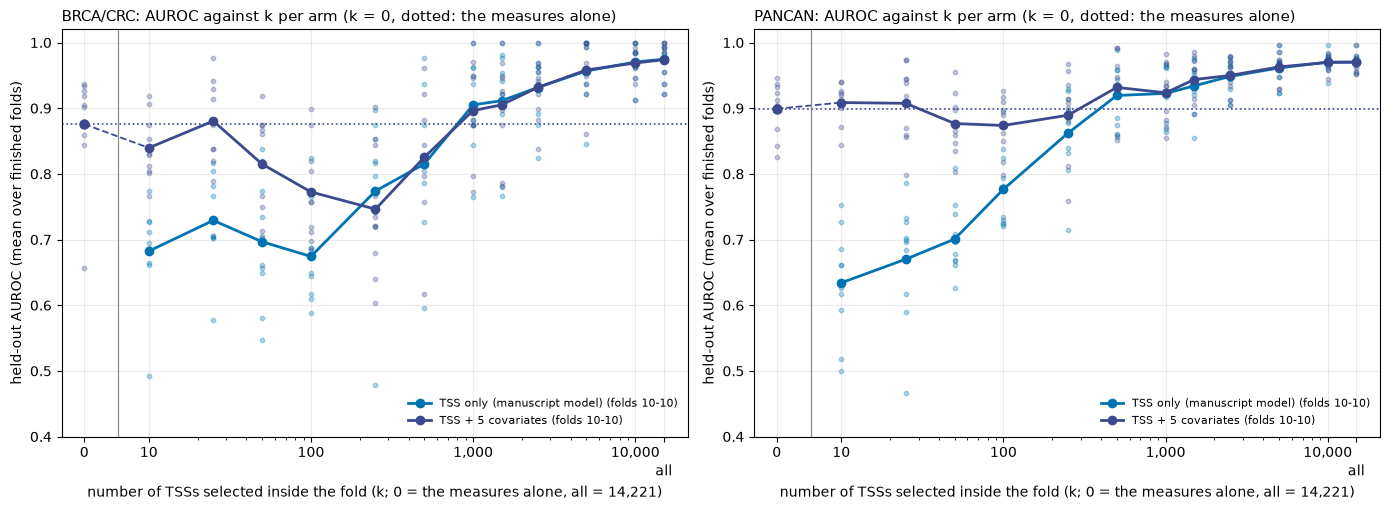

In [3]:
if HAVE:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    for ax, (task, tl) in zip(axes, TASKS.items()):
        draw_auc_vs_k(ax, task, arms_present(task),
                      lambda arm, m: f"{ARMS[arm]['label']} (folds {int(m['count'].min())}-{int(m['count'].max())})",
                      ylim=(0.4, 1.02), point_size=10)
        ax.set_ylabel("held-out AUROC (mean over finished folds)")
        ax.set_title(f"{tl}: AUROC against k per arm (k = 0, dotted: the measures alone)", loc="left", fontsize=10.5)
        ax.legend(fontsize=8, frameon=False, loc="lower right")
    plt.tight_layout(); savefig(fig, "figS14_auc_vs_k.png", dpi=220, bbox_inches="tight"); plt.show()


## 4. Selected number of TSSs per fold

The *k*, feature type and classifier chosen per fold by the inner CV, per arm.

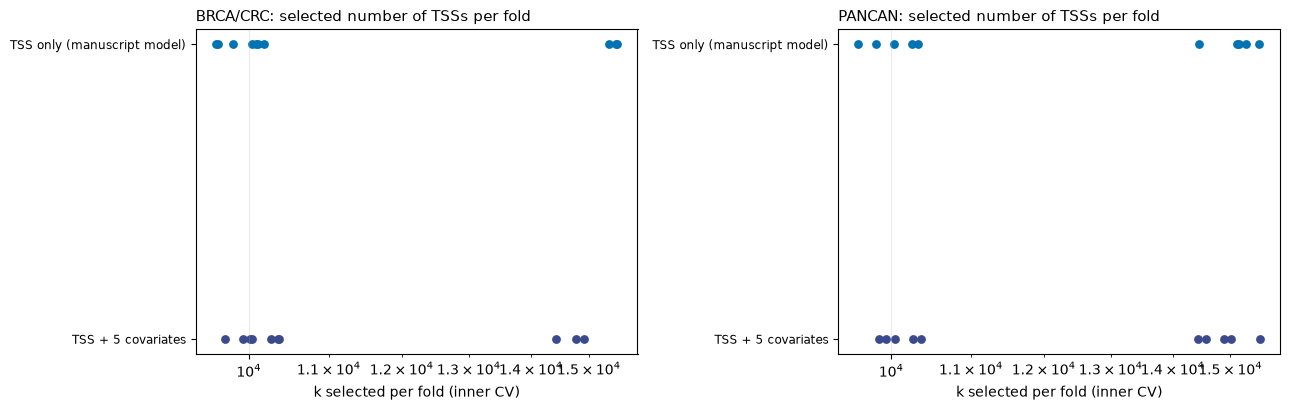

,task,arm,fold,k_selected,feature,classifier,inner_cv_auc,test_auc,n_k_available,complete
0,brca_crc,TSS only (manuscript model),1,10000,griffin_diff,Support Vector Machine,0.972,0.912,12,True
1,brca_crc,TSS only (manuscript model),2,10000,griffin_diff,Support Vector Machine,0.974,0.963,12,True
2,brca_crc,TSS only (manuscript model),3,10000,griffin_diff,Support Vector Machine,0.961,0.985,12,True
3,brca_crc,TSS only (manuscript model),4,10000,griffin_diff,Support Vector Machine,0.968,1.000,12,True
4,brca_crc,TSS only (manuscript model),5,15000,griffin_diff,Support Vector Machine,0.974,0.922,12,True
5,brca_crc,TSS only (manuscript model),6,15000,griffin_diff,Support Vector Machine,0.968,1.000,12,True
6,brca_crc,TSS only (manuscript model),7,10000,griffin_diff,Support Vector Machine,0.956,0.969,12,True
7,brca_crc,TSS only (manuscript model),8,10000,griffin_diff,Support Vector Machine,0.960,0.984,12,True
8,brca_crc,TSS only (manuscript model),9,10000,griffin_diff,Support Vector Machine,0.959,0.945,12,True
9,brca_crc,TSS only (manuscript model),10,15000,griffin_diff,Support Vector Machine,0.970,0.977,12,True


In [4]:
if HAVE and tuned is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (task, tl) in zip(axes, TASKS.items()):
        arms_ = arms_present(task)
        for i, arm in enumerate(arms_):
            tt = tuned[(tuned["task"] == task) & (tuned["arm"] == arm)].sort_values("fold")
            ax.scatter(tt["k_selected"] * (1 + 0.04 * np.random.default_rng(i).uniform(-1, 1, len(tt))), np.full(len(tt), i), s=28, color=ARMS[arm]["color"])
        ax.set_yticks(range(len(arms_))); ax.set_yticklabels([ARMS[a]["label"] for a in arms_], fontsize=8.5); ax.invert_yaxis()
        ax.set_xscale("log"); ax.set_xlabel("k selected per fold (inner CV)"); ax.grid(axis="x", alpha=0.25)
        ax.set_title(f"{tl}: selected number of TSSs per fold", loc="left", fontsize=10.5)
    plt.tight_layout(); savefig(fig, "figS14_k_selected.png", dpi=200, bbox_inches="tight"); plt.show()
    with pd.option_context("display.width", 240, "display.max_rows", 200):
        display(tuned.assign(arm=tuned["arm"].map(lambda a: ARMS[a]["label"]))[["task", "arm", "fold", "k_selected", "feature", "classifier", "inner_cv_auc", "test_auc", "n_k_available", "complete"]].round(3))

## 5. What the models do with the covariates

5a. Block permutation importance: AUROC drop on each test fold when all covariate columns (or the whole
TSS block) are shuffled across samples, against *k*.

5b. For fold models with explicit weights (LR and linear SVM coefficients on standardised columns; tree
feature importances): the share of TSS |weights| each covariate's |weight| exceeds, and single-covariate
permutation drops.

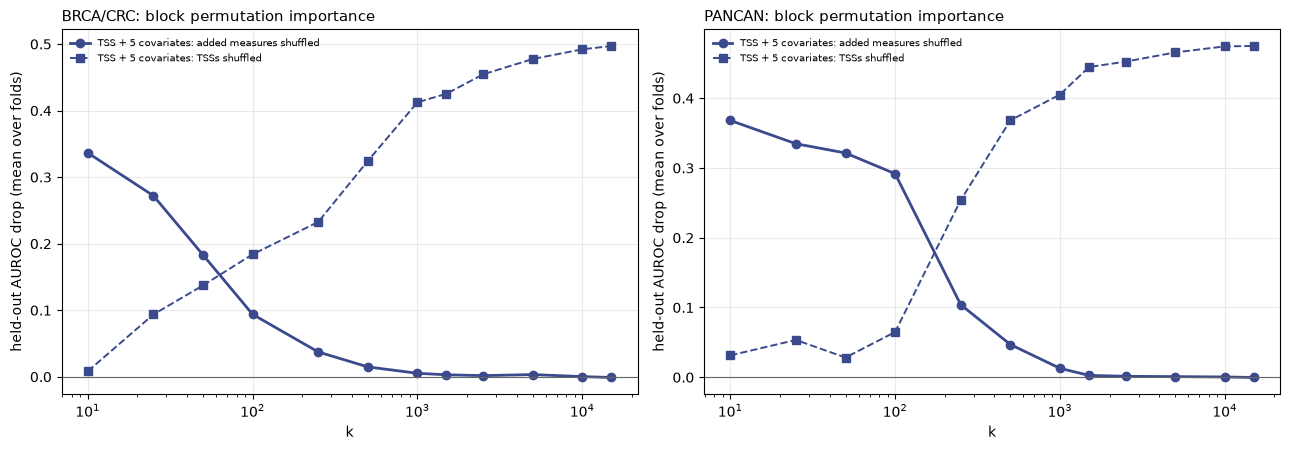

In [5]:
if HAVE and blocks is not None:
    aug = blocks[blocks["mode"] == "augment"]
    if len(aug):
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
        for ax, (task, tl) in zip(axes, TASKS.items()):
            for arm in [a for a in arms_present(task) if a.startswith("cov_")]:
                g = aug[(aug["task"] == task) & (aug["arm"] == arm)].groupby("k")[["perm_drop_covariates_mean", "perm_drop_tss_mean"]].mean()
                if g.empty:
                    continue
                ax.plot(g.index, g["perm_drop_covariates_mean"], marker="o", color=ARMS[arm]["color"], linewidth=2, label=f"{ARMS[arm]['label']}: added measures shuffled")
                ax.plot(g.index, g["perm_drop_tss_mean"], marker="s", linestyle="--", color=ARMS[arm]["color"], linewidth=1.4, label=f"{ARMS[arm]['label']}: TSSs shuffled")
            ax.set_xscale("log"); ax.axhline(0, color="0.4", linewidth=0.8); ax.grid(alpha=0.25)
            ax.set_xlabel("k"); ax.set_ylabel("held-out AUROC drop (mean over folds)"); ax.set_title(f"{tl}: block permutation importance", loc="left", fontsize=10.5)
            ax.legend(fontsize=7, frameon=False)
        plt.tight_layout(); savefig(fig, "figS14_block_importance.png", dpi=200, bbox_inches="tight"); plt.show()

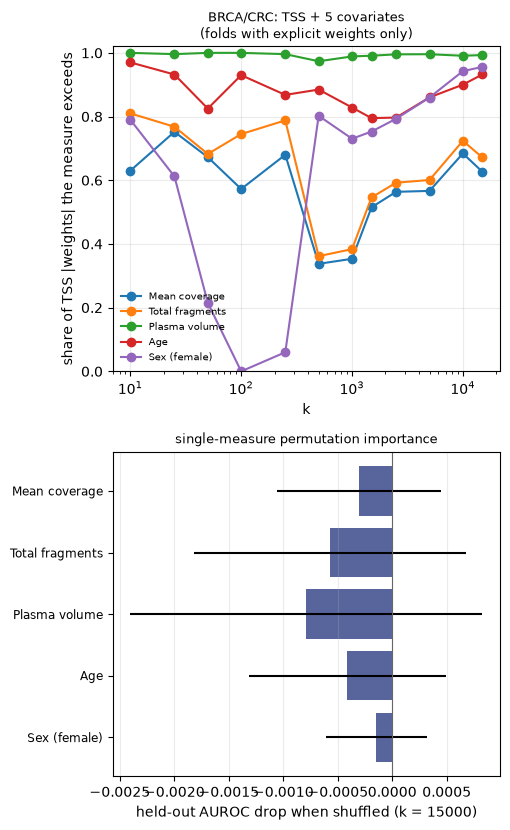

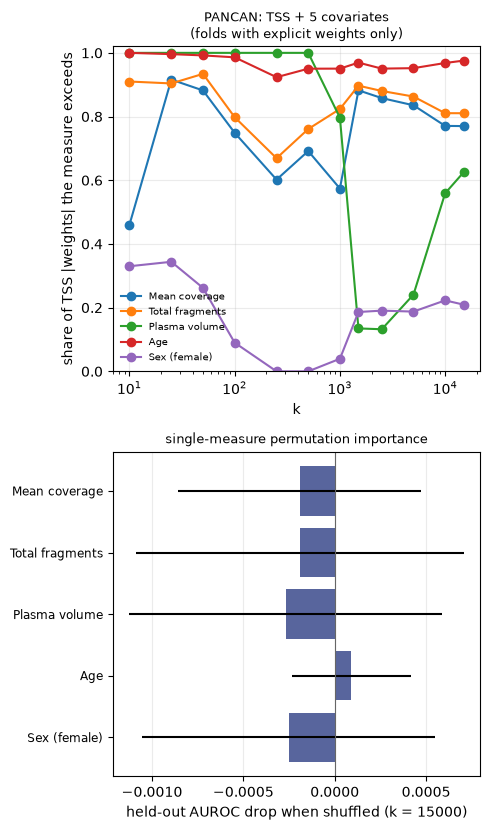

In [6]:
if HAVE and covs is not None and len(covs):
    for task, tl in TASKS.items():
        arms_ = [a for a in arms_present(task) if ((covs["task"] == task) & (covs["arm"] == a)).any()]
        if not arms_:
            continue
        fig, axes = plt.subplots(2, len(arms_), figsize=(5.2 * len(arms_), 8.4), squeeze=False)
        for j, arm in enumerate(arms_):
            g = covs[(covs["task"] == task) & (covs["arm"] == arm)]
            names = list(dict.fromkeys(g["covariate"]))
            ax = axes[0, j]
            for name in names:
                gg = g[g["covariate"] == name].groupby("k")["quantile_vs_tss"].mean()
                ax.plot(gg.index, gg.to_numpy(), marker="o", linewidth=1.5, label=LABELS.get(name, name))
            ax.set_xscale("log"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.25); ax.set_xlabel("k")
            ax.set_ylabel("share of TSS |weights| the measure exceeds"); ax.set_title(f"{tl}: {ARMS[arm]['label']}\n(folds with explicit weights only)", fontsize=9.5)
            ax.legend(fontsize=7, frameon=False, loc="lower left")
            ax = axes[1, j]
            kmax = g["k"].max(); gk = g[g["k"] == kmax].groupby("covariate")["perm_drop"].agg(["mean", "std"]).reindex(names)
            ax.barh(range(len(names)), gk["mean"], xerr=gk["std"].fillna(0), color=ARMS[arm]["color"], alpha=0.85)
            ax.set_yticks(range(len(names))); ax.set_yticklabels([LABELS.get(n, n) for n in names], fontsize=8.5); ax.invert_yaxis()
            ax.axvline(0, color="0.4", linewidth=0.8); ax.grid(axis="x", alpha=0.25)
            ax.set_xlabel(f"held-out AUROC drop when shuffled (k = {int(kmax)})"); ax.set_title("single-measure permutation importance", fontsize=9.5)
        plt.tight_layout(); savefig(fig, f"figS14_covariate_weights_{task}.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. Checks of the source data

Every arm has one row per outer fold, and the fold AUROCs recomputed from the stored predictions equal the stored values.


In [7]:
if HAVE:
    for (task, arm, k), g in folds.groupby(["task", "arm", "k"]):
        assert g["fold"].is_unique, (task, arm, k)
        assert g["fold"].between(1, 10).all(), (task, arm, k)
    if preds is not None:
        chk = preds.groupby(["task", "arm", "k", "fold"]).apply(lambda q: roc_auc_score(q["y_true"], q["score"]), include_groups=False).rename("auc").reset_index()
        m = chk.merge(folds[["task", "arm", "k", "fold", "test_auc"]], on=["task", "arm", "k", "fold"])
        assert np.allclose(m["auc"], m["test_auc"], atol=1e-9)
    print("structure OK")
else:
    print("no data yet")

structure OK


<!-- assembled-figure -->
## 7. Figure S14 (assembled)

- a, b: held-out AUROC against *k* per arm, covariate-only panel at *k* = 0 (dotted level), tuned
  fold-mean AUROC in the legend;
- c, d: block permutation importance at every *k* (covariate vs TSS columns shuffled);
- e, f: share of TSS |weights| each confounder's |weight| exceeds, fold mean per *k*.

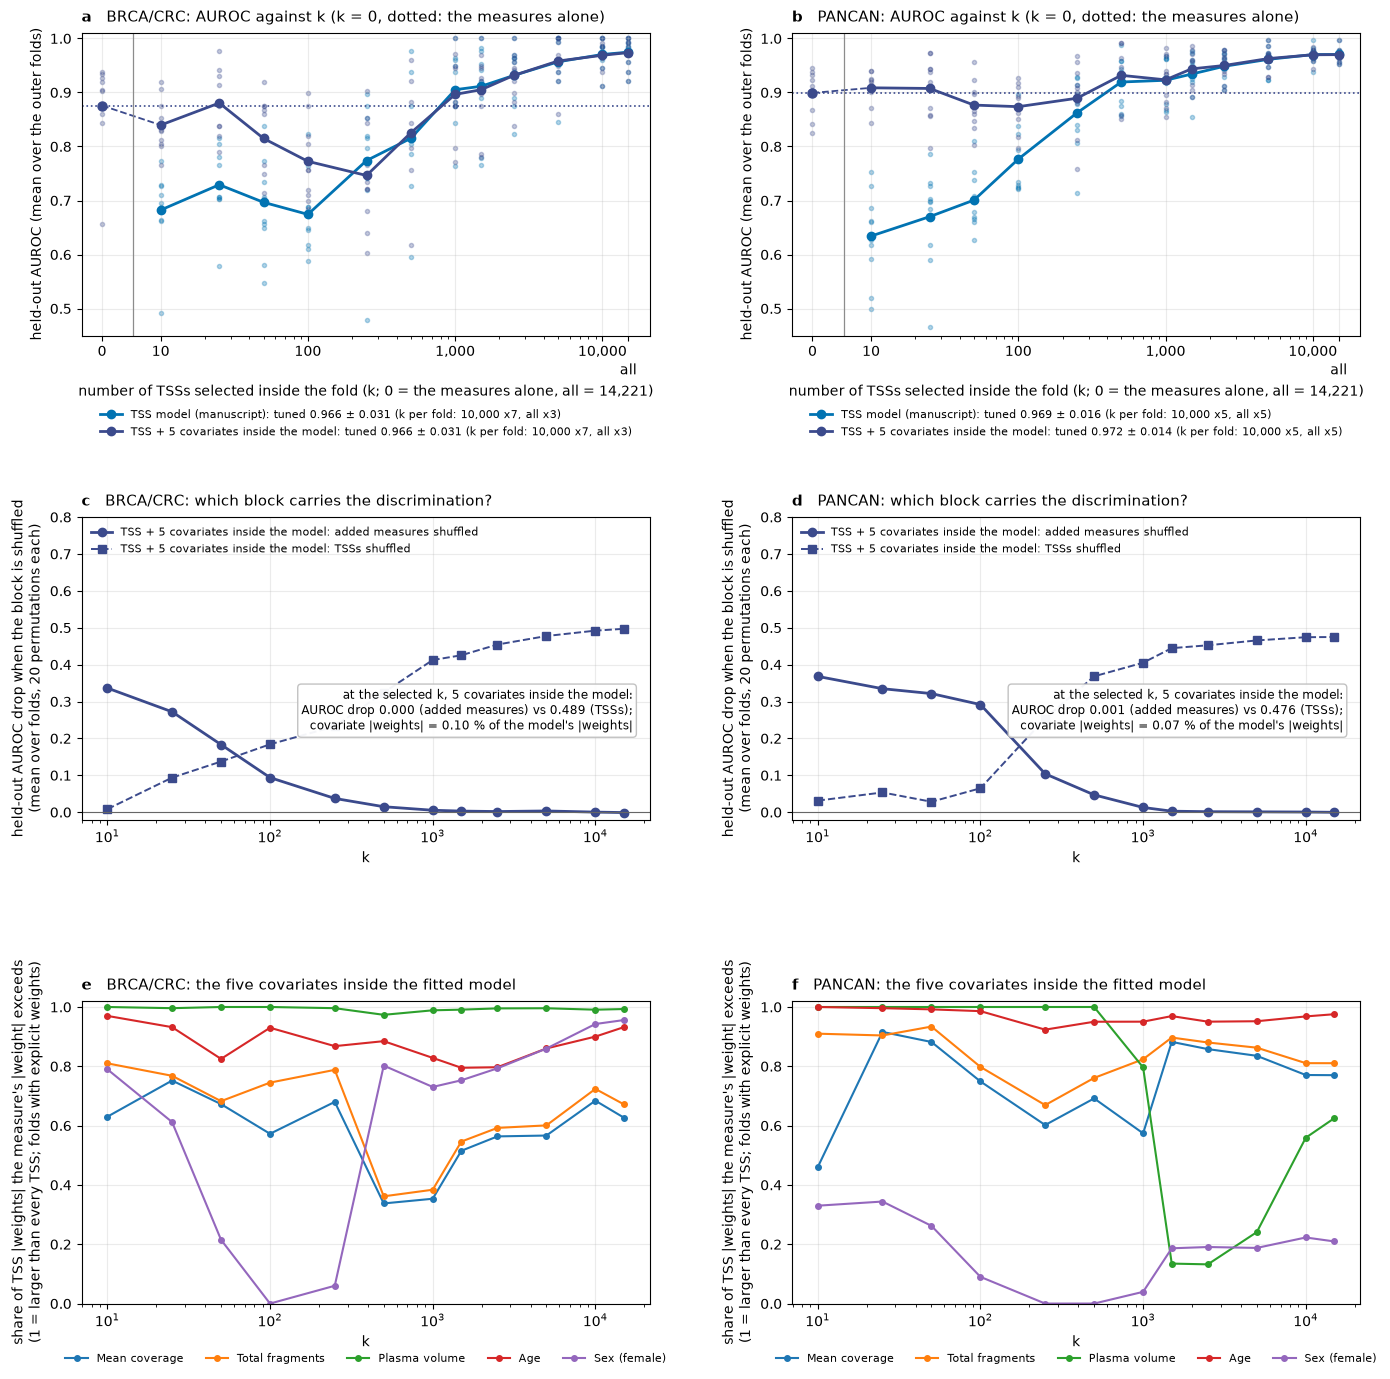

Figure S14 written to output\no_deep\figS14.png and .pdf


In [8]:
if not (HAVE and tuned is not None and blocks is not None and covs is not None):
    print("Figure S14 is not assembled: source data incomplete")
else:
    FIG_ARMS = ["none", "cov_techdemo5"]
    FIG_LABEL = {"none": "TSS model (manuscript)", "cov_techdemo5": "TSS + 5 covariates inside the model"}
    PERM_ARM = "cov_techdemo5"
    aug = blocks[blocks["mode"] == "augment"]

    def ttl(ax, letter, text, size=11):
        ax.set_title(f"$\\bf{{{letter}}}$   {text}", loc="left", fontsize=size, pad=8)

    fig = plt.figure(figsize=(16.5, 16.5))
    gs = fig.add_gridspec(3, 2, hspace=0.6, wspace=0.25)
    for j, (task, tl) in enumerate(TASKS.items()):
        present = [a for a in FIG_ARMS if a in arms_present(task)]
        # --- a, b: AUROC vs k ---------------------------------------------------------------
        ax = fig.add_subplot(gs[0, j])

        def k_label(arm, m, task=task):
            tt = tuned[(tuned["task"] == task) & (tuned["arm"] == arm)]
            ks = ", ".join(f"{k_text(k)} x{n}" for k, n in tt["k_selected"].value_counts().sort_index().items())
            partial = "" if len(tt) == 10 else f"; {len(tt)}/10 folds"
            return f"{FIG_LABEL[arm]}: tuned {tt['test_auc'].mean():.3f} \u00b1 {tt['test_auc'].std():.3f} (k per fold: {ks}{partial})"

        draw_auc_vs_k(ax, task, present, k_label)
        ax.set_ylabel("held-out AUROC (mean over the outer folds)")
        ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.21))
        ttl(ax, "ab"[j], f"{tl}: AUROC against k (k = 0, dotted: the measures alone)")
        # the same panel as a separate figure
        fig1, ax1 = plt.subplots(figsize=(8, 4.2))
        draw_auc_vs_k(ax1, task, present, k_label)
        ax1.set_ylabel("held-out AUROC (mean over the outer folds)")
        ax1.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.28))
        ax1.set_title(f"{tl}: AUROC against k (k = 0, dotted: the measures alone)", loc="left", fontsize=11)
        savefig(fig1, f"figS14_k_{task}.png", dpi=220, bbox_inches="tight"); plt.close(fig1)
        # --- c, d: block permutation importance ---------------------------------------------
        ax = fig.add_subplot(gs[1, j])
        for arm in [a for a in present if a.startswith("cov_")]:
            g = aug[(aug["task"] == task) & (aug["arm"] == arm)].groupby("k")[["perm_drop_covariates_mean", "perm_drop_tss_mean"]].mean()
            if g.empty:
                continue
            ax.plot(g.index, g["perm_drop_covariates_mean"], marker="o", color=ARMS[arm]["color"], linewidth=2, label=f"{FIG_LABEL[arm]}: added measures shuffled")
            ax.plot(g.index, g["perm_drop_tss_mean"], marker="s", linestyle="--", color=ARMS[arm]["color"], linewidth=1.4, label=f"{FIG_LABEL[arm]}: TSSs shuffled")
        tt = tuned[(tuned["task"] == task) & (tuned["arm"] == PERM_ARM)]
        at_k = aug[(aug["task"] == task) & (aug["arm"] == PERM_ARM)].merge(tt[["fold", "k_selected"]].rename(columns={"k_selected": "k"}), on=["fold", "k"])
        if len(at_k):
            share = (at_k["covariate_abs_weight_sum"] / (at_k["covariate_abs_weight_sum"] + at_k["tss_abs_weight_sum"])).mean()
            ax.text(0.97, 0.36, f"at the selected k, {FIG_LABEL[PERM_ARM].replace('TSS + ', '')}:\n"
                                f"AUROC drop {round(at_k['perm_drop_covariates_mean'].mean(), 3) + 0.0:.3f} (added measures) vs {at_k['perm_drop_tss_mean'].mean():.3f} (TSSs);\n"
                                f"covariate |weights| = {100 * share:.2f} % of the model's |weights|",
                    transform=ax.transAxes, fontsize=8.6, va="center", ha="right", bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.75", alpha=0.95))
        ax.set_xscale("log"); ax.axhline(0, color="0.4", linewidth=0.8); ax.grid(alpha=0.25); ax.set_ylim(-0.02, 0.8)
        ax.set_xlabel("k"); ax.set_ylabel("held-out AUROC drop when the block is shuffled\n(mean over folds, 20 permutations each)")
        ax.legend(fontsize=7.6, frameon=False, loc="upper left", ncol=1)
        ttl(ax, "cd"[j], f"{tl}: which block carries the discrimination?")
        # --- e, f: each confounder among the TSS weights ----------------------------------------
        ax = fig.add_subplot(gs[2, j])
        g = covs[(covs["task"] == task) & (covs["arm"] == PERM_ARM)]
        for name in list(dict.fromkeys(g["covariate"])):
            gg = g[g["covariate"] == name].groupby("k")["quantile_vs_tss"].mean()
            ax.plot(gg.index, gg.to_numpy(), marker="o", linewidth=1.5, markersize=4, label=LABELS.get(name, name))
        ax.set_xscale("log"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.25); ax.set_xlabel("k")
        ax.set_ylabel("share of TSS |weights| the measure's |weight| exceeds\n(1 = larger than every TSS; folds with explicit weights)")
        ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=5)
        ttl(ax, "ef"[j], f"{tl}: the five covariates inside the fitted model")
    savefig(fig, "figS14.png", dpi=220, bbox_inches="tight"); savefig(fig, "figS14.pdf", bbox_inches="tight")
    plt.show()
    print(f"Figure S14 written to {out_path('figS14.png')} and .pdf")